# IMDB Sentiment Classification with Fine-Tuned BERT

This is the **executed assignment notebook** for binary sentiment classification
on the IMDB 50K dataset. It uses the supplied preprocessed/tokenized dataset;
data-cleaning and tokenization code are intentionally not repeated here.

The included checkpoint can be loaded directly for inference—retraining is not
required.

## Experiment design

- **Base model:** `google-bert/bert-base-uncased` (109.5M parameters)
- **Training data:** 25,000 IMDB reviews
- **Held-out test data:** 25,000 IMDB reviews
- **Fine-tuned parameters:** final BERT encoder block, pooler, and classification head (7.68M; 7.01%)
- **Frozen parameters:** embeddings and the first 11 BERT encoder blocks
- **Maximum sequence length:** 128 tokens
- **Optimization:** AdamW, learning rate `3e-5`, weight decay `0.01`, 10% linear warm-up
- **Training:** one epoch, batch size 16, seed 42

This CPU-aware partial fine-tuning keeps the complete pretrained BERT model in
the saved checkpoint while updating the highest-level language features and the
sentiment classifier.

In [1]:
from pathlib import Path
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from transformers import AutoModelForSequenceClassification, AutoTokenizer

PROJECT_ROOT = Path.cwd()
MODEL_DIR = PROJECT_ROOT / "model" / "imdb_bert_finetuned"
DATA_PATH = PROJECT_ROOT / "data" / "imdb_bert_tokenized_50k.npz"
RESULTS_PATH = PROJECT_ROOT / "training_results.json"

assert MODEL_DIR.exists(), f"Model directory not found: {MODEL_DIR}"
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"
assert RESULTS_PATH.exists(), f"Results file not found: {RESULTS_PATH}"

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Project root: {PROJECT_ROOT}")

Python: 3.13.5
PyTorch: 2.10.0+cpu
Transformers: 5.5.4
CUDA available: False
Project root: C:\Users\Admin\Downloads\IMDB_BERT\IMDB_BERT_Assignment_Complete


## Load the supplied preprocessed dataset

In [2]:
dataset = np.load(DATA_PATH)

dataset_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "examples": [len(dataset["train_labels"]), len(dataset["test_labels"])],
        "sequence_length": [dataset["train_input_ids"].shape[1], dataset["test_input_ids"].shape[1]],
        "negative": [(dataset["train_labels"] == 0).sum(), (dataset["test_labels"] == 0).sum()],
        "positive": [(dataset["train_labels"] == 1).sum(), (dataset["test_labels"] == 1).sum()],
    }
)
dataset_summary

,split,examples,sequence_length,negative,positive
0,train,25000,128,12500,12500
1,test,25000,128,12500,12500


## Training record

The exact script used for training is included as `scripts/train_model.py`.
The following cell displays the recorded output from the completed run. To
repeat the expensive training step, run that script from the extracted project
folder. The notebook itself defaults to loading the finished checkpoint.

In [3]:
training_log = (PROJECT_ROOT / "training_log.txt").read_text(encoding="utf-8")
print(training_log)

PyTorch 2.8.0+cu128; device=cpu; threads=8
Configuration: epochs=1, batch_size=16, max_length=128, lr=3e-05
Trainable parameters: 7,680,002/109,483,778 (7.01%)
Epoch 1/1 step 100/1,563 loss=0.6780 accuracy=0.5737
Epoch 1/1 step 200/1,563 loss=0.6266 accuracy=0.6416
Epoch 1/1 step 300/1,563 loss=0.5654 accuracy=0.6946
Epoch 1/1 step 400/1,563 loss=0.5257 accuracy=0.7253
Epoch 1/1 step 500/1,563 loss=0.4938 accuracy=0.7478
Epoch 1/1 step 600/1,563 loss=0.4702 accuracy=0.7626
Epoch 1/1 step 700/1,563 loss=0.4555 accuracy=0.7740
Epoch 1/1 step 800/1,563 loss=0.4445 accuracy=0.7824
Epoch 1/1 step 900/1,563 loss=0.4330 accuracy=0.7899
Epoch 1/1 step 1,000/1,563 loss=0.4268 accuracy=0.7948
Epoch 1/1 step 1,100/1,563 loss=0.4202 accuracy=0.7994
Epoch 1/1 step 1,200/1,563 loss=0.4152 accuracy=0.8028
Epoch 1/1 step 1,300/1,563 loss=0.4094 accuracy=0.8063
Epoch 1/1 step 1,400/1,563 loss=0.4074 accuracy=0.8082
Epoch 1/1 step 1,500/1,563 loss=0.4054 accuracy=0.8102
Epoch 1/1 step 1,563/1,563 loss=0

## Held-out test results

In [4]:
results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
metrics = results["test_metrics"]

metric_table = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1", "Loss"],
        "Value": [
            metrics["accuracy"],
            metrics["precision"],
            metrics["recall"],
            metrics["f1"],
            metrics["loss"],
        ],
    }
)
metric_table.style.format({"Value": "{:.4f}"})

,Metric,Value
0,Accuracy,0.8587
1,Precision,0.8657
2,Recall,0.8491
3,F1,0.8573
4,Loss,0.3241


In [5]:
report = pd.DataFrame(metrics["classification_report"]).T
report

,precision,recall,f1-score,support
negative,0.851951,0.86824,0.860018,12500.00000
positive,0.865672,0.84912,0.857316,12500.00000
accuracy,0.858680,0.85868,0.858680,0.85868
macro avg,0.858811,0.85868,0.858667,25000.00000
weighted avg,0.858811,0.85868,0.858667,25000.00000


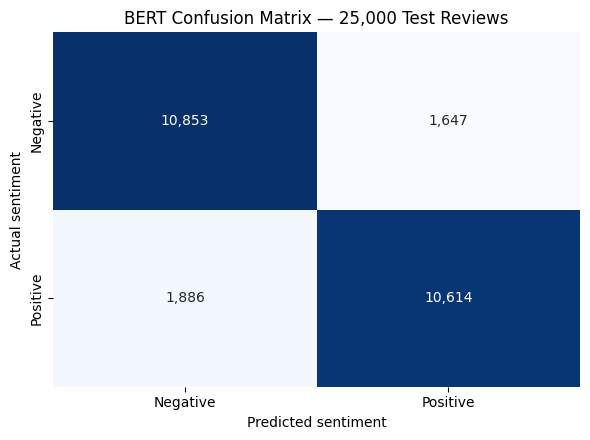

In [6]:
confusion = np.asarray(metrics["confusion_matrix"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    confusion,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.title("BERT Confusion Matrix — 25,000 Test Reviews")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

## Load the saved fine-tuned weights

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_DIR,
    local_files_only=True,
    use_safetensors=True,
).to(device)
model.eval()

parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Loaded checkpoint from: {MODEL_DIR}")
print(f"Device: {device}")
print(f"Parameters: {parameter_count:,}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded checkpoint from: C:\Users\Admin\Downloads\IMDB_BERT\IMDB_BERT_Assignment_Complete\model\imdb_bert_finetuned
Device: cpu
Parameters: 109,483,778


## Direct-inference function

In [8]:
@torch.inference_mode()
def predict_sentiment(texts):
    """Return negative/positive probabilities for one string or a list of strings."""
    if isinstance(texts, str):
        texts = [texts]

    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt",
    ).to(device)

    logits = model(**encoded).logits
    probabilities = torch.softmax(logits, dim=-1).cpu().numpy()
    predictions = probabilities.argmax(axis=1)

    return pd.DataFrame(
        {
            "text": texts,
            "prediction": ["POSITIVE" if value == 1 else "NEGATIVE" for value in predictions],
            "negative_probability": probabilities[:, 0],
            "positive_probability": probabilities[:, 1],
        }
    )

sample_reviews = [
    "A genuinely wonderful film with excellent performances and a moving story.",
    "This was painfully slow, badly acted, and a complete waste of time.",
    "The acting was strong, although the ending felt rushed and disappointing.",
]

predict_sentiment(sample_reviews)

,text,prediction,negative_probability,positive_probability
0,A genuinely wonderful film with excellent perf...,POSITIVE,0.009942,0.990058
1,"This was painfully slow, badly acted, and a co...",NEGATIVE,0.833317,0.166683
2,"The acting was strong, although the ending fel...",POSITIVE,0.351775,0.648225


## Enter your own review

In [14]:
your_review = "it is good"
predict_sentiment(your_review)

,text,prediction,negative_probability,positive_probability
0,it is good,POSITIVE,0.111099,0.888901


## Interpretation and limitations

The model achieved **85.87% accuracy** and **85.73% F1** on the untouched
25,000-review test split. Most errors are likely to involve sarcasm, mixed
sentiment, context beyond 128 tokens, or domain-specific language.

This checkpoint is intended for an academic sentiment-classification exercise.
It should not be used as a general-purpose judgment system or for high-stakes
decisions. Its labels are restricted to `NEGATIVE` and `POSITIVE`.

## Dataset references

- Prepared 50K train/test files: [GitHub repository](https://github.com/laxmimerit/IMDB-Movie-Reviews-Large-Dataset-50k)
- Original dataset: [Stanford Large Movie Review Dataset](https://ai.stanford.edu/~amaas/data/sentiment/)

The exact tokenized dataset used by this notebook is included in
`data/imdb_bert_tokenized_50k.npz`, with hashes and provenance stored in
`data/dataset_metadata.json`.